# Zero-Shot and Few-Shot Prompting with MedGemma
This notebook explores zero-shot and few-shot prompting techniques for chest X-ray (CXR) image classification using MedGemma.<br>
https://developers.google.com/health-ai-developer-foundations/medgemma

## GPU Configuration

In [1]:
import os

# GPU Configuration
GPU = 1  # Change this to your desired GPU device
os.environ["CUDA_VISIBLE_DEVICES"] = f"{GPU}"

print(f"Using GPU device: {GPU}")

Using GPU device: 1


## Import Libraries

In [2]:
# Core libraries
import pandas as pd
import numpy as np
import torch
import json

# Visualization
import matplotlib.pyplot as plt

# ML/AI libraries
from transformers import pipeline
from PIL import Image

# Utilities
from tqdm import tqdm

# MedGemma utilities
# Install with: uv add git+https://github.com/theodapamede/DLUtils.git
from dlutils.MedGemma import *

## Data Preparation
We'll load and prepare our CXR dataset for zero-shot evaluation

In [3]:
# Data setup
BASE = '/mnt/NAS3/CXR/Datathon25_CXR_samples/'

# Load and shuffle data
meta = pd.read_csv('./datathon25_cxr_samples.csv')
meta = meta.sample(frac=1, random_state=5656)

# Create train/test split
meta.loc[:, 'Split'] = ['Train'] * 800 + ['Test'] * 200
meta = meta.reset_index(drop=True)

# Add full image paths
meta['ImagePath'] = BASE + meta['ImagePath']

print(f"Dataset shape: {meta.shape}")
print(f"Train samples: {(meta['Split'] == 'Train').sum()}")
print(f"Test samples: {(meta['Split'] == 'Test').sum()}")

meta.head()

Dataset shape: (1000, 5)
Train samples: 800
Test samples: 200


,empi_anon,AccessionNumber_anon,ImagePath,Pathology,Split
0,61685815,5863640761177624,/mnt/NAS3/CXR/Datathon25_CXR_samples/61685815/...,Pleural Effusion,Train
1,71361841,8840724976111750,/mnt/NAS3/CXR/Datathon25_CXR_samples/71361841/...,Pneumothorax,Train
2,69665808,135355407742,/mnt/NAS3/CXR/Datathon25_CXR_samples/69665808/...,No Finding,Train
3,86597294,2659208101971565,/mnt/NAS3/CXR/Datathon25_CXR_samples/86597294/...,Enlarged Cardiomediastinum,Train
4,21892125,656536978946,/mnt/NAS3/CXR/Datathon25_CXR_samples/21892125/...,No Finding,Train


### Dataset Overview
Let's examine the distribution of pathologies across our train and test splits to understand class balance.

In [4]:
meta.groupby('Split').Pathology.value_counts()

Split  Pathology                 
Test   Lung Opacity                   43
       Pleural Effusion               41
       Pneumothorax                   41
       Enlarged Cardiomediastinum     38
       No Finding                     37
Train  No Finding                    163
       Enlarged Cardiomediastinum    162
       Pleural Effusion              159
       Pneumothorax                  159
       Lung Opacity                  157
Name: count, dtype: int64

- No class bias: Results won't be skewed toward overrepresented classes

### Preparing Evaluation Data
We'll convert our test set into a list of dictionaries for easier processing during zero-shot evaluation.

In [5]:
# Prepare evaluation dataset
meta_eval = meta[meta['Split'] == 'Test']
print(f"Test samples: {len(meta_eval)}")

# Convert to list of dictionaries for easier processing
examples_eval = []
for i in tqdm(range(len(meta_eval)), desc="Preparing evaluation data"):
    examples_eval.append(meta_eval.iloc[i].to_dict())

Test samples: 200


Preparing evaluation data: 100%|██████████| 200/200 [00:00<00:00, 17575.13it/s]


## Loading MedGemma Model
We'll load the MedGemma-4B model for zero-shot CXR classification. This model is specifically designed for medical image analysis tasks.

In [6]:
# Load the MedGemma model
model_id = "google/medgemma-4b-it"
print("🔄 Loading MedGemma model...")

try:
    pipe = pipeline(
        "image-text-to-text",
        model=model_id,
        torch_dtype=torch.bfloat16,
        device="cuda",
    )
    
    # Configure for deterministic output
    pipe.model.generation_config.do_sample = False
    print("✅ MedGemma model loaded successfully!")
    
except Exception as e:
    print(f"❌ Error loading model: {str(e)}")
    print("💡 Make sure you have sufficient GPU memory and the model is available.")
    raise

🔄 Loading MedGemma model...


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
Device set to use cuda


✅ MedGemma model loaded successfully!


## Zero-Shot Prompting
Zero-shot prompting asks the model to perform a task without providing examples—relying solely on the task description and the model's pre-training.

### Key Characteristics
**Advantages**:
- Simple and fast implementation
- No training required
- Leverages model's existing knowledge

**Disadvantages**:

- Limited task-specific adaptation
- Inconsistent output formatting
- Performance depends heavily on pre-training data

#### Structured vs. Unstructured Prompting

**Unstructured Prompt** (informal, conversational):
```
"Show me the patient's X-ray from last year and their most recent one, and tell me what's changed. The patient is John Doe."
```

**Structured Prompt** (organized, explicit format):
```json
[
  {
    "role": "system",
    "content": "You are an expert radiologist analyzing medical images."
  },
  {
    "role": "user", 
    "content": [
      {"type": "text", "text": "Compare these chest X-rays and identify changes"},
      {"type": "image", "image": "..."}
    ]
  }
]
```
#### Key Components

**System Prompt**: Establishes the AI's role, expertise, and behavioral guidelines at the conversation start. Acts as a "constitution" defining how the model should respond throughout the entire interaction.

**User Prompt**: Contains the specific task instruction and input data (text, images, etc.) for each individual request or turn in the conversation.

#### Why Structured Prompting Matters

Structured prompting organizes communication with AI models using explicit roles and formatted inputs. This approach is particularly valuable for:

- **Complex multimodal tasks** involving text, images, and other data types
- **Clear role definition** for domain-specific expertise

We'll create a class to handle zero-shot prompting for CXR classification. This class will format prompts and prepare data for the model.

In [7]:
class ZeroShotPrompt:
    """Zero-shot prompting strategy for CXR pathology classification"""
    
    def __init__(self, classes):
        self.classes = classes
        self.options = "\n".join(classes)
    
    def format_prompt(self, prompt=None):
        """Create a simple, direct prompt for classification"""
        if prompt is not None:
            return prompt
        else:
            return f"What is the most likely pathology shown in the chest x-ray image?\n\nOptions:\n{self.options}\n\nPlease respond with only the pathology class (e.g., 'Pneumothorax')."
    
    def format_data(self, example, prompt=None):
        """Format a single example for the model"""
        example_copy = example.copy()  # Don't modify original
        example_copy["messages"] = [
            {
                "role": "system", 
                "content": [{"type": "text", "text": "You are an expert radiologist."}]
            },
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": self.format_prompt(prompt)},
                    {"type": "image", "image": preprocess(Image.open(example['ImagePath']))} 
                ],
            },
        ]
        
        return example_copy

### Zero-Shot Prompt Example
Let's examine how our ZeroShotPrompt class formats a single example for the model.

CONVERSATION PROMPT

[SYSTEM]
----------------------------------------
You are an expert radiologist.

[USER]
----------------------------------------
What is the most likely pathology shown in the chest x-ray image?

Options:
Pleural Effusion
Pneumothorax
No Finding
Enlarged Cardiomediastinum
Lung Opacity

Please respond with only the pathology class (e.g., 'Pneumothorax').
  📷 PIL Image - Mode: RGB, Size: 3032x2520


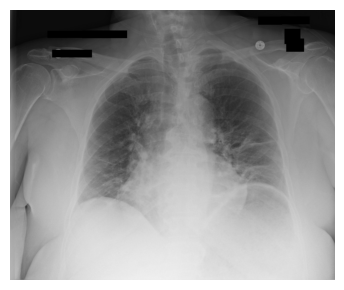

In [8]:
# Initialize zero-shot prompter with available classes
classes = list(meta['Pathology'].unique())
zeroshot = ZeroShotPrompt(classes)

# Select an example to demonstrate formatting
example = examples_eval[56]

# Format the example for model input
formatted_example = zeroshot.format_data(example)

print_prompt(formatted_example['messages'])

### Zero-Shot Prediction
Let's run the model on our formatted example to see zero-shot classification in action.

🔄 Running zero-shot prediction...
Model prediction: Lung Opacity
True pathology: Lung Opacity


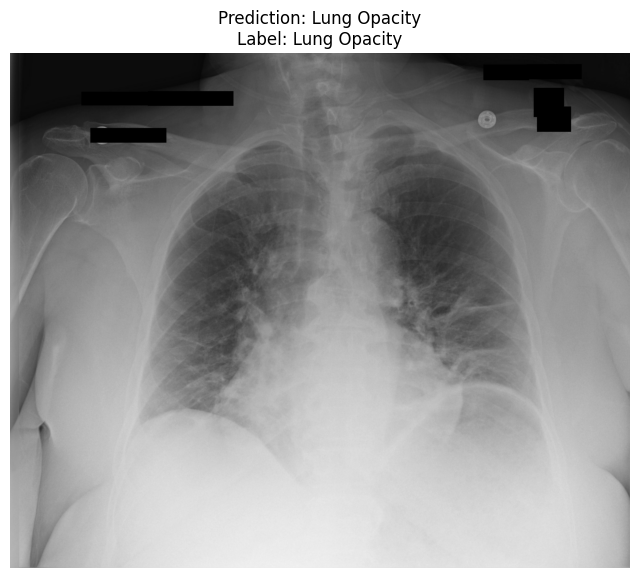

In [9]:
# Run zero-shot prediction on the example
print("🔄 Running zero-shot prediction...")

output = pipe(
    text=formatted_example["messages"],  # Structured prompt with system + user messages
    max_new_tokens=40,                   # Limit response length for concise classification
    return_full_text=False,              # Return only generated text, not input prompt
)

print(f"Model prediction: {output[0]['generated_text'].strip()}")
print(f"True pathology: {example['Pathology']}")

# Display the prediction with image
display_prediction(output, example, figsize=(8, 8))

### Try your own prompt and other examples

CONVERSATION PROMPT

[SYSTEM]
----------------------------------------
You are an expert radiologist.

[USER]
----------------------------------------
What is the most likely pathology shown in the chest x-ray image?
            Options: No Finding, Lung Opacity, Enlarged Cardiomediastinum, Pleural Effusion, Pneumothorax.
            Select one answer from the options.
  📷 PIL Image - Mode: RGB, Size: 3032x2520


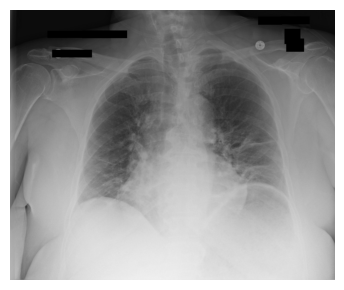

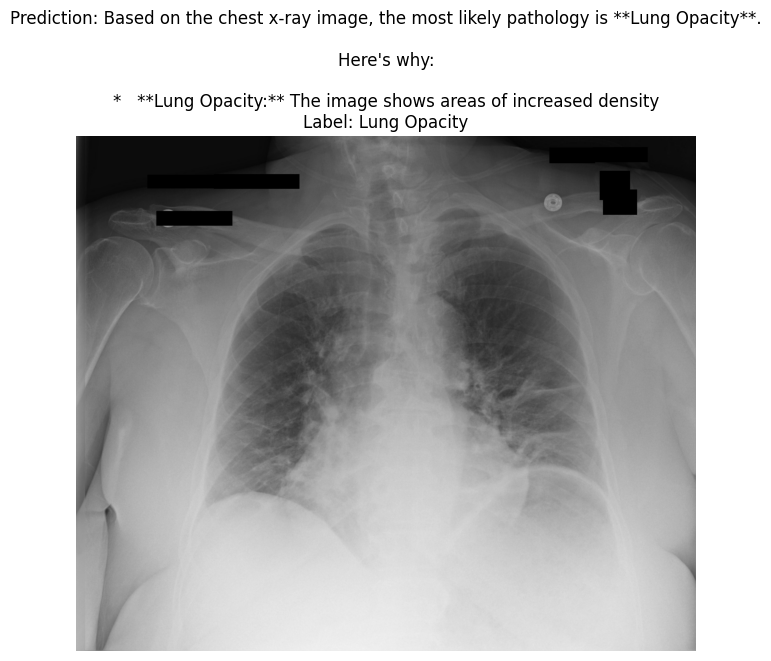

In [10]:
# Try your own prompt

prompt = f"What is the most likely pathology shown in the chest x-ray image?\n \
           Options: No Finding, Lung Opacity, Enlarged Cardiomediastinum, Pleural Effusion, Pneumothorax.\n \
           Select one answer from the options."

example = examples_eval[56] # you can select other sample
formatted_example = zeroshot.format_data(example, prompt)
print_prompt(formatted_example['messages'])

output = pipe(
    text=formatted_example["messages"],
    max_new_tokens=40,
    return_full_text=False,
)

display_prediction(output, example, figsize=(8,8))

### Batch Zero-Shot Evaluation
Now we'll evaluate the model's zero-shot performance across our entire test set (200 samples). This will give us comprehensive metrics for each pathology class.

#### Prediction Postprocessing
Since the model generates free text responses, we need to extract the predicted class from the output. This function searches for valid pathology labels in the model's response.

In [11]:
def postprocess_prediction(prediction, classes):
    """
    Extract the predicted class from model's free text response.
    
    Args:
        prediction: Model output containing generated text
        classes: List of valid pathology class names
        
    Returns:
        str: Matched class name, or -1 if no match found
    """
    # Extract the model's response text
    response_text = prediction[0]["generated_text"].strip()
    
    # Search for exact label match (case-insensitive)
    for label in classes:
        if label.lower() in response_text.lower():
            return label
    
    # Return -1 if no valid class found in response
    return -1

#### Run Inference

In [12]:
# Run zero-shot evaluation on full test set
print(f"🔄 Evaluating zero-shot prompting on {len(examples_eval)} samples...")
print("This may take a few minutes...")

try:
    # Format all examples for model input
    formatted_data = [zeroshot.format_data(example) for example in examples_eval]
    
    # Run inference in batches to manage GPU memory
    batch_size = 10  # Reduce if you encounter memory issues
    all_outputs = []
    
    for i in range(0, len(formatted_data), batch_size):
        batch_end = min(i + batch_size, len(formatted_data))
        batch_data = formatted_data[i:batch_end]
        batch_num = i // batch_size + 1
        total_batches = (len(formatted_data) + batch_size - 1) // batch_size
        
        print(f"Processing batch {batch_num}/{total_batches} (samples {i+1}-{batch_end})")
        
        # Run batch inference
        batch_outputs = pipe(
            text=[example["messages"] for example in batch_data],  # Extract message lists
            max_new_tokens=40,                                     # Limit response length
            return_full_text=False,                                # Return only generated text
        )
        all_outputs.extend(batch_outputs)
    
    # Extract predictions from model outputs
    predictions = [postprocess_prediction(out, classes) for out in all_outputs]
    references = [example["Pathology"] for example in examples_eval]
    
    # Compute evaluation metrics
    metrics = compute_accuracy(predictions, references)
    
    # Display results
    print("\n📊 Zero-Shot Results:")
    print("=" * 30)
    print(f"Accuracy: {metrics['accuracy']:.3f} ({metrics['accuracy']*100:.1f}%)")
    print(f"Valid predictions: {metrics['valid_predictions']}/{metrics['total_samples']}")
    print(f"Correct predictions: {metrics['correct_predictions']}/{metrics['valid_predictions']}")

except Exception as e:
    print(f"❌ Error during evaluation: {str(e)}")
    print("💡 Try reducing batch_size or eval_size if you encounter memory issues.")
    raise

🔄 Evaluating zero-shot prompting on 200 samples...
This may take a few minutes...
Processing batch 1/20 (samples 1-10)
Processing batch 2/20 (samples 11-20)
Processing batch 3/20 (samples 21-30)
Processing batch 4/20 (samples 31-40)
Processing batch 5/20 (samples 41-50)
Processing batch 6/20 (samples 51-60)
Processing batch 7/20 (samples 61-70)
Processing batch 8/20 (samples 71-80)


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Processing batch 9/20 (samples 81-90)
Processing batch 10/20 (samples 91-100)
Processing batch 11/20 (samples 101-110)
Processing batch 12/20 (samples 111-120)
Processing batch 13/20 (samples 121-130)
Processing batch 14/20 (samples 131-140)
Processing batch 15/20 (samples 141-150)
Processing batch 16/20 (samples 151-160)
Processing batch 17/20 (samples 161-170)
Processing batch 18/20 (samples 171-180)
Processing batch 19/20 (samples 181-190)
Processing batch 20/20 (samples 191-200)

📊 Zero-Shot Results:
Accuracy: 0.485 (48.5%)
Valid predictions: 200/200
Correct predictions: 97/200


#### Error Analysis

Let's look at where the model makes mistakes to understand its limitations.

In [13]:
results_zeroshot = analyze_errors(predictions, references, all_outputs, meta)

🔍 Error Analysis:
Correct predictions: 97
Incorrect predictions: 103
Invalid predictions: 0

❌ Common mistakes:
  Enlarged Cardiomediastinum → No Finding: 22 times
  Lung Opacity → No Finding: 18 times
  Pneumothorax → No Finding: 17 times
  Pneumothorax → Pleural Effusion: 8 times
  Enlarged Cardiomediastinum → Lung Opacity: 8 times
  Pneumothorax → Lung Opacity: 7 times
  Pleural Effusion → Lung Opacity: 6 times
  Pleural Effusion → No Finding: 4 times
  Enlarged Cardiomediastinum → Pleural Effusion: 3 times
  No Finding → Lung Opacity: 3 times
  Lung Opacity → Pleural Effusion: 3 times
  Pleural Effusion → Enlarged Cardiomediastinum: 2 times
  No Finding → Pleural Effusion: 1 times
  No Finding → Enlarged Cardiomediastinum: 1 times

📊 Subgroup Accuracies:
Pleural Effusion Accuracy: 0.71
Pneumothorax Accuracy: 0.22
No Finding Accuracy: 0.86
Enlarged Cardiomediastinum Accuracy: 0.13
Lung Opacity Accuracy: 0.51


### Summary

In this notebook, we implemented and evaluated **zero-shot prompting** for chest X-ray (CXR) pathology classification:

#### What we accomplished:
1. ✅ Created a structured zero-shot prompting strategy with expert persona
2. ✅ Tested the approach on individual examples with clear visualization
3. ✅ Evaluated performance across the full test set (200 samples)
4. ✅ Analyzed results across 5 pathology classes 

#### Key insights:
- **Simple and Fast**: Zero-shot prompting requires no training
- **Baseline Performance**: Provides a solid starting point for comparison with other approaches
- **Medical Domain**: MedGemma's pre-training enables reasonable performance on CXR classification
- **Structured Prompts**: Clear role definition and explicit options improve response quality

#### When to use zero-shot prompting:
- ✅ Quick prototyping and baseline establishment
- ✅ Tasks where the model has strong pre-training coverage (like CXRs)
- ✅ Limited time or resources for example preparation
- ✅ Initial exploration of model capabilities

### Limitations observed:
- ❌ May struggle with subtle distinctions between similar pathologies
- ❌ Less control over output format
- ❌ Occasional invalid responses requiring postprocessing

**Next steps**: Compare these zero-shot results with few-shot prompting 

## Few-Shot Prompting 

We will demonstrate **few-shot prompting** - providing the model with examples before asking it to classify new images. <br>
This helps the model understand the desired output format and learn patterns specific to your task.

**Advantages:**
- Better task understanding
- Improved output consistency
- Can capture more domain-specific patterns
- More control over model behavior

**Disadvantages:**
- Requires careful example selection
- Longer prompts (more tokens)
- Example bias can affect results

### Selecting Few-Shot Examples
For few-shot prompting, we need to select representative examples from our training set. We'll use one example per pathology class to create a balanced set of support examples:


Few-shot support examples:


(<Figure size 900x600 with 6 Axes>,
 array([<Axes: title={'center': 'Enlarged Cardiomediastinum'}>,
        <Axes: title={'center': 'Lung Opacity'}>,
        <Axes: title={'center': 'No Finding'}>,
        <Axes: title={'center': 'Pleural Effusion'}>,
        <Axes: title={'center': 'Pneumothorax'}>, <Axes: >], dtype=object))

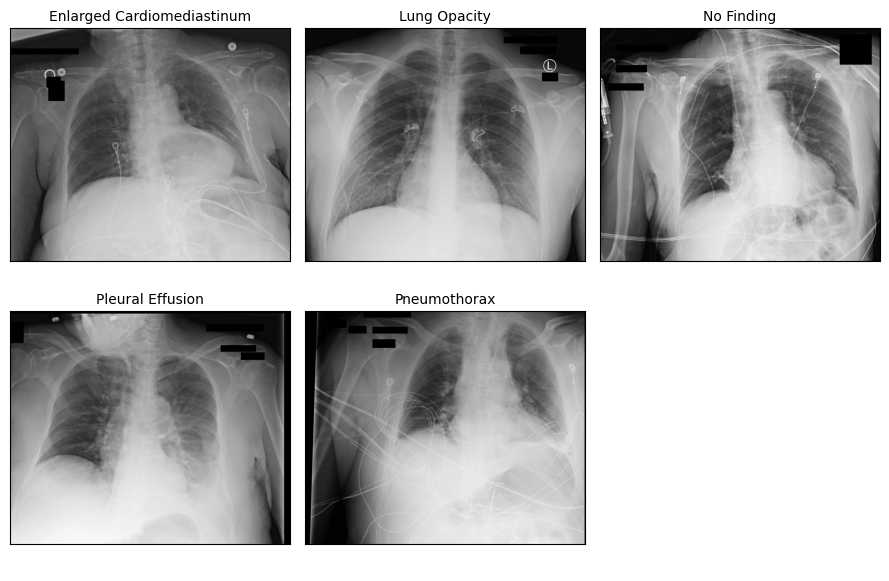

In [14]:
# Select few-shot examples from training set
meta_train = meta[meta['Split'] == 'Train']

# Sample one representative example per pathology class
meta_train = meta_train.groupby('Pathology').sample(n=1, random_state=5656)

# Visualize the selected few-shot examples
print(f"\nFew-shot support examples:")
plot_images_grid(list(meta_train['ImagePath']), list(meta_train['Pathology']))

#### Converting Examples to Dictionary Format
Convert our selected few-shot examples to the dictionary format.

In [15]:
# Convert selected training examples to dictionary format

examples_train = []
for i in tqdm(range(len(meta_train))):
    examples_train.append(meta_train.iloc[i].to_dict())

100%|██████████| 5/5 [00:00<00:00, 12115.26it/s]


### Few-Shot Prompt Strategy
This class builds on our zero-shot approach by adding support examples to help the model understand the task better.

In [16]:
class FewShotPrompt:
    """Few-shot prompting with intelligent example selection for Hugging Face pipelines"""
    
    def __init__(self, classes, support_examples):
        self.classes = classes
        self.options = "\n".join(classes)        
        self.support_examples = support_examples      
    
    def format_for_pipeline(self, query_example):
        """
        Formats the few-shot examples and query into a structured
        list of messages for a chat pipeline.
        """
        # 1. Define the system message
        system_message = {
            "role": "system",
            "content": [{"type": "text", "text": "You are an expert radiologist."}]
        }

        # 2. Build the user message by interleaving text and images
        user_content = [
            {"type": "text", "text": "Here are some examples of chest x-ray image classification:"}
        ]

        # Add the few-shot examples with original phrasing
        for i, support_ex in enumerate(self.support_examples, 1):
            # Combine Question and Answer into one text block per example
            example_text = (
                f"Example {i}:\n"
                f"Question: What is the most likely pathology shown in the following chest x-ray image?\n"
                f"Answer: {support_ex['Pathology']}"
            )
            user_content.append({"type": "text", "text": example_text})
            
            # Append the preprocessed image for this example
            image = Image.open(support_ex['ImagePath'])
            user_content.append({"type": "image", "image": preprocess(image)})

        # Add the final query text with original phrasing
        query_image_num = len(self.support_examples) + 1
        query_text = (
            f"Now classify chest x-ray image {query_image_num}:\n"
            f"Question: What is the most likely pathology shown in the following chest x-ray image?\n\n"
            f"Options:\n{self.options}\n\n"
            "Please respond with only the pathology class. (e.g., 'Pneumothorax')"
        )
        user_content.append({"type": "text", "text": query_text})
        
        # Append the final query image
        query_image = Image.open(query_example['ImagePath'])
        user_content.append({"type": "image", "image": preprocess(query_image)})
        
        # 3. Combine into the final messages list
        messages = [system_message, {"role": "user", "content": user_content}]

        # Return in a dictionary for the pipeline
        return {"messages": messages}

### Few-Shot Prompt Example
Let's see how our FewShotPrompt class formats the support examples and query into a structured prompt:


Formatted few-shot prompt:
CONVERSATION PROMPT

[SYSTEM]
----------------------------------------
You are an expert radiologist.

[USER]
----------------------------------------
Here are some examples of chest x-ray image classification:
Example 1:
Question: What is the most likely pathology shown in the following chest x-ray image?
Answer: Enlarged Cardiomediastinum
  📷 PIL Image - Mode: RGB, Size: 3032x2520


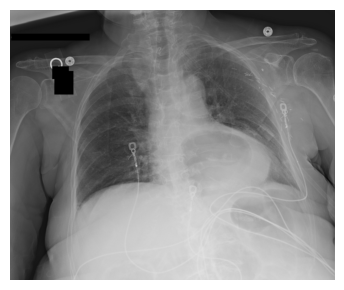

Example 2:
Question: What is the most likely pathology shown in the following chest x-ray image?
Answer: Lung Opacity
  📷 PIL Image - Mode: RGB, Size: 3028x2517


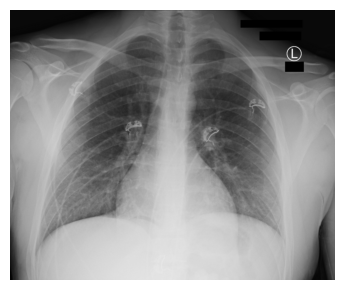

Example 3:
Question: What is the most likely pathology shown in the following chest x-ray image?
Answer: No Finding
  📷 PIL Image - Mode: RGB, Size: 3032x2517


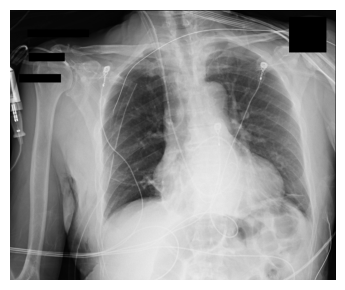

Example 4:
Question: What is the most likely pathology shown in the following chest x-ray image?
Answer: Pleural Effusion
  📷 PIL Image - Mode: RGB, Size: 3032x2520


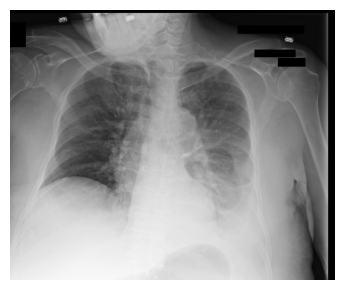

Example 5:
Question: What is the most likely pathology shown in the following chest x-ray image?
Answer: Pneumothorax
  📷 PIL Image - Mode: RGB, Size: 3032x2520


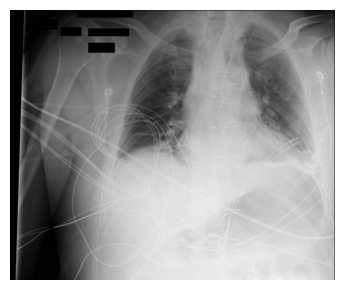

Now classify chest x-ray image 6:
Question: What is the most likely pathology shown in the following chest x-ray image?

Options:
Pleural Effusion
Pneumothorax
No Finding
Enlarged Cardiomediastinum
Lung Opacity

Please respond with only the pathology class. (e.g., 'Pneumothorax')
  📷 PIL Image - Mode: RGB, Size: 3032x2520


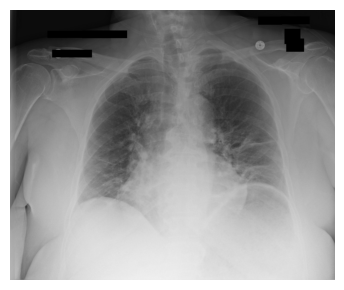

In [17]:
# Initialize few-shot prompter with support examples
fewshot = FewShotPrompt(list(meta['Pathology'].unique()), examples_train)

# Use the same example as in zero-shot for comparison
example = examples_eval[56]

# Format the few-shot prompt
single_prompt = fewshot.format_for_pipeline(example)

# Display the formatted prompt
print(f"\nFormatted few-shot prompt:")
print_prompt(single_prompt["messages"])

#### Few-Shot Prediction Example
Now let's run the model with our few-shot prompt to see how providing examples affects the classification.

🔄 Running few-shot prediction...


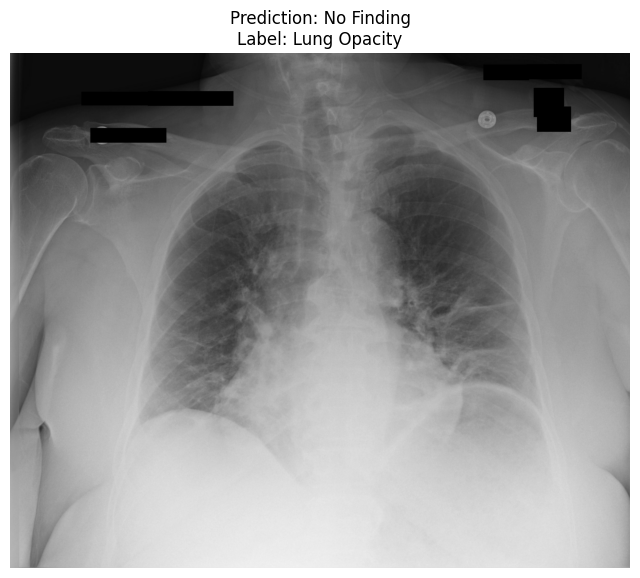

In [18]:
# Run few-shot prediction on the example
print("🔄 Running few-shot prediction...")

output = pipe(
    text=single_prompt['messages'],      # Structured prompt with examples + query
    max_new_tokens=40,                   # Limit response length for classification
    return_full_text=False               # Return only generated text
)

# Display the prediction with image
display_prediction(output, example, figsize=(8, 8))

### Few-Shot Batch Evaluation
Now we'll evaluate few-shot performance across our entire test set. This will show how providing examples impacts classification accuracy compared to zero-shot prompting.

In [19]:
# Run few-shot evaluation on full test set
print(f"🔄 Evaluating few-shot prompting on {len(examples_eval)} samples...")
print("This may take a few minutes...")

try:
    # Format all examples with support examples included
    formatted_data = [fewshot.format_for_pipeline(example) for example in examples_eval]
    
    # Run inference in batches to manage GPU memory
    batch_size = 10  # Reduce if you encounter memory issues
    all_outputs = []
    
    for i in range(0, len(formatted_data), batch_size):
        batch_end = min(i + batch_size, len(formatted_data))
        batch_data = formatted_data[i:batch_end]
        batch_num = i // batch_size + 1
        total_batches = (len(formatted_data) + batch_size - 1) // batch_size
        
        print(f"Processing batch {batch_num}/{total_batches} (samples {i+1}-{batch_end})")
        
        # Run batch inference with few-shot prompts
        batch_outputs = pipe(
            text=[example["messages"] for example in batch_data],  # Extract message lists
            max_new_tokens=40,                                     # Limit response length
            return_full_text=False,                                # Return only generated text
        )
        all_outputs.extend(batch_outputs)
    
    # Extract predictions from model outputs
    predictions = [postprocess_prediction(out, classes) for out in all_outputs]
    references = [example["Pathology"] for example in examples_eval]
    
    # Compute evaluation metrics
    metrics = compute_accuracy(predictions, references)
    
    # Display results
    print("\n📊 Few-Shot Results:")
    print("=" * 30)
    print(f"Accuracy: {metrics['accuracy']:.3f} ({metrics['accuracy']*100:.1f}%)")
    print(f"Valid predictions: {metrics['valid_predictions']}/{metrics['total_samples']}")
    print(f"Correct predictions: {metrics['correct_predictions']}/{metrics['valid_predictions']}")

except Exception as e:
    print(f"❌ Error during evaluation: {str(e)}")
    print("💡 Try reducing batch_size or eval_size if you encounter memory issues.")
    raise

🔄 Evaluating few-shot prompting on 200 samples...
This may take a few minutes...
Processing batch 1/20 (samples 1-10)
Processing batch 2/20 (samples 11-20)
Processing batch 3/20 (samples 21-30)
Processing batch 4/20 (samples 31-40)
Processing batch 5/20 (samples 41-50)
Processing batch 6/20 (samples 51-60)
Processing batch 7/20 (samples 61-70)
Processing batch 8/20 (samples 71-80)
Processing batch 9/20 (samples 81-90)
Processing batch 10/20 (samples 91-100)
Processing batch 11/20 (samples 101-110)
Processing batch 12/20 (samples 111-120)
Processing batch 13/20 (samples 121-130)
Processing batch 14/20 (samples 131-140)
Processing batch 15/20 (samples 141-150)
Processing batch 16/20 (samples 151-160)
Processing batch 17/20 (samples 161-170)
Processing batch 18/20 (samples 171-180)
Processing batch 19/20 (samples 181-190)
Processing batch 20/20 (samples 191-200)

📊 Few-Shot Results:
Accuracy: 0.315 (31.5%)
Valid predictions: 200/200
Correct predictions: 63/200


#### Error Analysis

Let's look at where the model makes mistakes to understand its limitations.

In [20]:
results_fewshot = analyze_errors(predictions, references, all_outputs, meta)

🔍 Error Analysis:
Correct predictions: 63
Incorrect predictions: 137
Invalid predictions: 0

❌ Common mistakes:
  Lung Opacity → No Finding: 38 times
  Enlarged Cardiomediastinum → No Finding: 36 times
  Pneumothorax → No Finding: 31 times
  Pleural Effusion → No Finding: 17 times
  Pneumothorax → Lung Opacity: 4 times
  Pleural Effusion → Lung Opacity: 3 times
  Pleural Effusion → Enlarged Cardiomediastinum: 2 times
  Pleural Effusion → Pneumothorax: 1 times
  Lung Opacity → Pneumothorax: 1 times
  No Finding → Enlarged Cardiomediastinum: 1 times
  Enlarged Cardiomediastinum → Lung Opacity: 1 times
  No Finding → Pneumothorax: 1 times
  Pneumothorax → Pleural Effusion: 1 times

📊 Subgroup Accuracies:
Pleural Effusion Accuracy: 0.44
Pneumothorax Accuracy: 0.12
No Finding Accuracy: 0.95
Enlarged Cardiomediastinum Accuracy: 0.03
Lung Opacity Accuracy: 0.09


# Zero-Shot vs Few-Shot Performance Analysis

This analysis compares the performance of zero-shot and few-shot prompting strategies for chest X-ray pathology classification using MedGemma.

## Key Findings

### Overall Performance Drop
- **Zero-shot: 48.5%** → **Few-shot: 31.5%** (17 percentage point drop!)

### Critical Pattern: "No Finding" Bias
The most striking change is the model's dramatically increased bias toward predicting "No Finding":

**Zero-shot mistakes:**
- Various pathologies → "No Finding": 61 total cases
- More diverse error patterns

**Few-shot mistakes:**
- Various pathologies → "No Finding": **122 total cases** (doubled!)
- Much more concentrated error pattern

### Class-Specific Impact

| Class | Zero-Shot Acc | Few-Shot Acc | Change |
|-------|---------------|--------------|---------|
| **No Finding** | 86% | **95%** | +9% ✅ |
| **Pleural Effusion** | 71% | 44% | -27% ❌ |
| **Lung Opacity** | 51% | 9% | -42% ❌ |
| **Pneumothorax** | 22% | 12% | -10% ❌ |
| **Enlarged Cardiomediastinum** | 13% | 3% | -10% ❌ |

## What might be Happening?

### 1. Conservative Bias Amplification
- The few-shot examples seem to have taught the model to be overly conservative
- When in doubt, predict "No Finding" (the safe choice)

### 2. Feature Confusion
- The support examples might contain ambiguous features
- Model is now second-guessing subtle pathological signs

### 3. Context Overload
- With 5 examples + query, the model might be overwhelmed
- Could be losing focus on the actual query image

### Key Takeaways

1. **More examples ≠ better performance** in specialized domains
4. **Example selection quality** is critical for few-shot success

## Recommendations

1. **Investigate example selection strategies** if pursuing few-shot approaches
2. **Validate thoroughly** before deploying in clinical settings